# Exploratory analysis – Bike Sharing (hourly)

EDA only: this notebook makes **no modelling decisions** and is not part of the experimental pipeline. It uses the same loader and split code as the experiments.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('..'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.pipeline import load_full_config, get_dataframe
from src.data.preprocess import chronological_split, dataset_statistics
cfg = load_full_config('configs/default.yaml')
df = get_dataframe(cfg)
split = chronological_split(len(df), cfg['split'])
df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,timestamp
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16,2011-01-01 00:00:00
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40,2011-01-01 01:00:00
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32,2011-01-01 02:00:00
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13,2011-01-01 03:00:00
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1,2011-01-01 04:00:00


## Split statistics
The test period (Aug–Dec 2012) has a higher mean and variance than the training period: the data are **not** exchangeable across the chronological split.

In [2]:
dataset_statistics(df, split, 'cnt')

,split,n,start,end,target_mean,target_std,target_median,target_min,target_max,temp_mean
0,train,10427,2011-01-01 00:00:00,2012-03-15 13:00:00,144.796874,134.620655,110.0,1,782,0.459676
1,calibration,3476,2012-03-15 14:00:00,2012-08-07 11:00:00,264.157365,215.525154,233.0,1,957,0.617641
2,test,3476,2012-08-07 12:00:00,2012-12-31 23:00:00,248.754603,220.516539,205.0,1,977,0.488257
3,all,17379,2011-01-01 00:00:00,2012-12-31 23:00:00,189.463088,181.387599,142.0,1,977,0.496987


## Hourly profile: working vs non-working days
Strong, regime-dependent daily pattern (commuting peaks on working days).

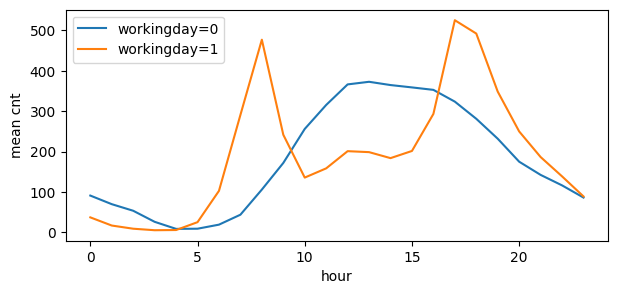

In [3]:
fig, ax = plt.subplots(figsize=(7,3))
for wd, g in df.groupby('workingday'):
    ax.plot(g.groupby('hr').cnt.mean(), label=f'workingday={wd}')
ax.legend(); ax.set_xlabel('hour'); ax.set_ylabel('mean cnt'); plt.show()

## Heteroscedasticity
The spread of `cnt` grows with its level → symmetric constant-width intervals are inefficient; motivates CQR.

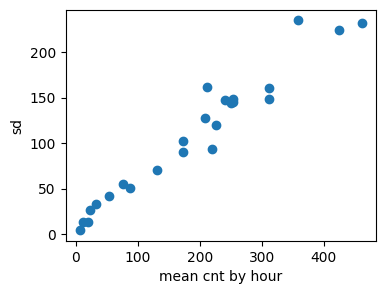

In [4]:
g = df.groupby('hr').cnt.agg(['mean','std'])
plt.figure(figsize=(4,3)); plt.scatter(g['mean'], g['std']); plt.xlabel('mean cnt by hour'); plt.ylabel('sd'); plt.show()

## Temporal gaps and trend

missing hours: 165


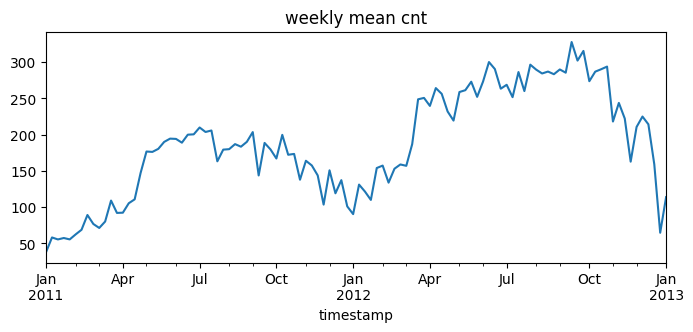

In [5]:
gaps = df.timestamp.diff().dt.total_seconds().div(3600)
print('missing hours:', int((gaps-1).clip(lower=0).sum()))
df.set_index('timestamp').cnt.resample('W').mean().plot(figsize=(8,3), title='weekly mean cnt'); plt.show()

## Time-identifying variables
`yr` alone separates 2011 from 2012 and correlates with the upward trend; `season`/`mnth` encode position in the year. The experiments therefore include a `no_time_id` feature set.

In [6]:
df.groupby('yr').cnt.describe()

,count,mean,std,min,25%,50%,75%,max
yr,,,,,,,,
0,8645.0,143.794448,133.797854,1.0,31.0,109.0,211.0,651.0
1,8734.0,234.666361,208.910941,1.0,53.0,191.0,347.0,977.0
